### IPD440 - APRENDIZAJE DE MAQUINAS
# Clase 15: Variational Autoencoders
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Introducción

<div align="center">
    <img src="img/wardrobe.png" alt="" width="40%" align="center" />
</div>

# Autoencoder

Red neuronal artificial que se utiliza para aprender codificaciones eficientes de datos no etiquetados.

<div align="center">
    <img src="img/autoencoder.png" alt="" width="60%" align="center" />
</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras.backend as K
from keras.datasets import fashion_mnist
from keras.models import Model
from keras import Input
from keras.layers import Dense, Lambda, Conv2D, Flatten, Conv2DTranspose, Reshape

In [2]:
print("Keras version:", tf.keras.__version__)
print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

Keras version: 2.12.0
TensorFlow version: 2.12.0
NumPy version: 1.23.5


## Fashion MNIST

<div align="center">
    <img src="img/Fashion-MNIST.jpg" alt="" width="60%" align="center" />
</div>

In [3]:
(x_train,y_train), (x_test,y_test) = fashion_mnist.load_data()

In [4]:
def preprocess(imgs):
    imgs = imgs.astype("float32") / 255.0
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=0.0)
    imgs = np.expand_dims(imgs, -1)
    return imgs

In [5]:
x_train = preprocess(x_train)
x_test = preprocess(x_test)

In [6]:
def plot_predictions(y_true, y_pred, image_dim=32):    
    if len(y_true) == len(y_pred):
        f, ax = plt.subplots(2, len(y_true), figsize=(15, 4))
        for i in range(len(y_true)):
            ax[0][i].imshow(np.reshape(y_true[i], (image_dim, image_dim)), aspect='auto', cmap='Greys')
            ax[0][i].set_title('Original')
            ax[0][i].axis('off')
            ax[1][i].imshow(np.reshape(y_pred[i], (image_dim, image_dim)), aspect='auto', cmap='Greys')
            ax[1][i].set_title('Reconstruction')
            ax[1][i].axis('off')
        plt.tight_layout()
    else:
        print("y_true and y_pred must be the same length!")

## La arquitectura del autoencoder

<div align="center">
    <img src="img/autoencoder-architecture-diagram.jpg" alt="" width="60%" align="center" />
</div>


## Encoder

In [7]:
encoder_input = Input(shape=(32, 32, 1), name="encoder_input")
x = Conv2D(32, (3, 3), strides=2, activation="relu", padding="same")(encoder_input)
x = Conv2D(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = Conv2D(128, (3, 3), strides=2, activation="relu", padding="same")(x)
shape_before_flattening = K.int_shape(x)[1:]
x = Flatten()(x)
encoder_output = Dense(2, name="encoder_output")(x)
encoder = Model(encoder_input, encoder_output)
encoder.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 encoder_input (InputLayer)  [(None, 32, 32, 1)]       0         
                                                                 
 conv2d (Conv2D)             (None, 16, 16, 32)        320       
                                                                 
 conv2d_1 (Conv2D)           (None, 8, 8, 64)          18496     
                                                                 
 conv2d_2 (Conv2D)           (None, 4, 4, 128)         73856     
                                                                 
 flatten (Flatten)           (None, 2048)              0         
                                                                 
 encoder_output (Dense)      (None, 2)                 4098      
                                                                 
Total params: 96,770
Trainable params: 96,770
Non-trainable p

## Decoder

In [8]:
decoder_input = Input(shape=(2,), name="decoder_input")
x = Dense(np.prod(shape_before_flattening))(decoder_input)
x = Reshape(shape_before_flattening)(x)
x = Conv2DTranspose(128, (3, 3), strides=2, activation="relu", padding="same")(x)
x = Conv2DTranspose(64, (3, 3), strides=2, activation="relu", padding="same")(x)
x = Conv2DTranspose(32, (3, 3), strides=2, activation="relu", padding="same")(x)
decoder_output = Conv2D(1, (3, 3), strides=1, activation="sigmoid", padding="same", name="decoder_output")(x)
decoder = Model(decoder_input, decoder_output)
decoder.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 decoder_input (InputLayer)  [(None, 2)]               0         
                                                                 
 dense (Dense)               (None, 2048)              6144      
                                                                 
 reshape (Reshape)           (None, 4, 4, 128)         0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 8, 8, 128)        147584    
 nspose)                                                         
                                                                 
 conv2d_transpose_1 (Conv2DT  (None, 16, 16, 64)       73792     
 ranspose)                                                       
                                                                 
 conv2d_transpose_2 (Conv2DT  (None, 32, 32, 32)       1846

## Autoencoder Model

In [9]:
autoencoder = Model(encoder_input, decoder(encoder_output))
autoencoder.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 encoder_input (InputLayer)  [(None, 32, 32, 1)]       0         
                                                                 
 conv2d (Conv2D)             (None, 16, 16, 32)        320       
                                                                 
 conv2d_1 (Conv2D)           (None, 8, 8, 64)          18496     
                                                                 
 conv2d_2 (Conv2D)           (None, 4, 4, 128)         73856     
                                                                 
 flatten (Flatten)           (None, 2048)              0         
                                                                 
 encoder_output (Dense)      (None, 2)                 4098      
                                                                 
 model_1 (Functional)        (None, 32, 32, 1)         2462

## La función de pérdida (Loss)

Elegir RMSE significa que una sobreestimación se penaliza de manera equivalente a una subestimación.

Por otro lado, binary cross-entropy loss es asimétrica: penaliza los errores hacia los extremos más que los errores hacia el centro. Por ejemplo, si el valor real del píxel es alto (por ejemplo, 0.7), generar un píxel con un valor de 0.8 se penaliza más que generar un píxel con un valor de 0.6. Si el valor de píxel real es bajo (digamos 0.3), entonces generar un píxel con valor 0.2 se penaliza más que generar un píxel con valor 0.4. Esto tiene el efecto de producir imágenes más borrrosas, pero a veces esto es deseable ya que RMSE puede generar bordes obviamente pixelizados.

In [10]:
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")

## Entrenamiento

In [11]:
autoencoder.fit(x_train, x_train, epochs=5, batch_size=100, shuffle=True, validation_data=(x_test, x_test));

Epoch 1/5
600/600 [==============================] - 86s 139ms/step - loss: 0.2984 - val_loss: 0.2635
Epoch 2/5
600/600 [==============================] - 110s 183ms/step - loss: 0.2594 - val_loss: 0.2587
Epoch 3/5
600/600 [==============================] - 116s 193ms/step - loss: 0.2555 - val_loss: 0.2557
Epoch 4/5
600/600 [==============================] - 106s 177ms/step - loss: 0.2533 - val_loss: 0.2535
Epoch 5/5
600/600 [==============================] - 109s 181ms/step - loss: 0.2517 - val_loss: 0.2528


## Espacio latente

<div align="center">
    <img src="img/latent-space.jpg" alt="" width="60%" align="center" />
</div>

In [12]:
def plot_latent_space(X, y, encoder):
    z = encoder.predict(X,verbose=0)
    plt.figure()
    plt.scatter(z[:, 0], z[:, 1], c=y, alpha=0.8, s=3, cmap="rainbow")
    plt.colorbar()
    plt.title("Espacio latente")    
    plt.show()

## Visualizando el espacio latente

Clases en Fashion MNIST: `{0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat', 5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'}`

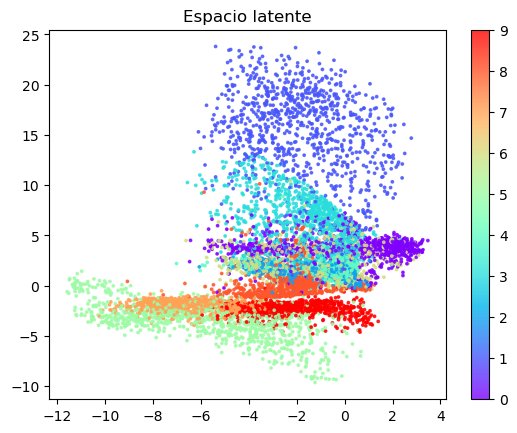

In [13]:
plot_latent_space(x_test, y_test, encoder)

## Reconstrucción

In [14]:
n_to_predict = 10
example_images = x_test[:n_to_predict]

In [15]:
predictions = autoencoder.predict(example_images, verbose=0)

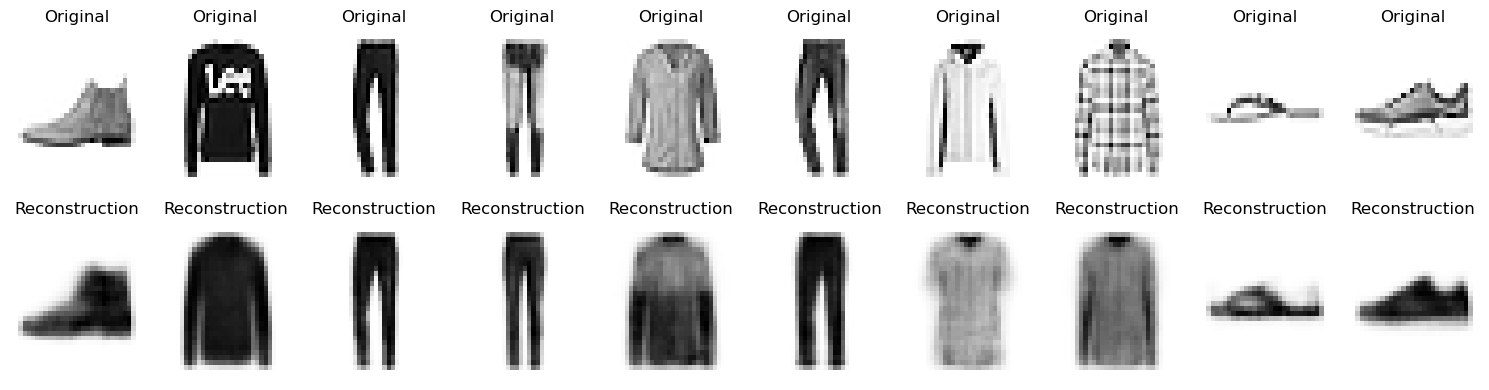

In [16]:
plot_predictions(example_images, predictions)

## Generando nuevas imágenes

In [17]:
def generating(X, encoder, decoder, figsize=8, grid_width=6, grid_height=3):
    z = encoder.predict(X, verbose=0)
    mins, maxs = np.min(z, axis=0), np.max(z, axis=0)
    sample = np.random.uniform(mins, maxs, size=(grid_width * grid_height, 2))
    reconstructions = decoder.predict(sample, verbose=0)
    fig = plt.figure(figsize=(20,7))
    plt.subplot(1, 2, 1)
    plt.scatter(z[:, 0], z[:, 1], c="black", alpha=0.5, s=2)
    plt.scatter(sample[:, 0], sample[:, 1], c="#00B0F0", alpha=1, s=40)
    plt.subplot(1, 2, 2)  
    plt.axis('off')
    fig.subplots_adjust(hspace=0.4, wspace=0.4)  
    slider = 0
    for i in range(grid_width * grid_height):
        k = i 
        if i % grid_width == 0:
            slider += grid_width
        k += slider
        ax = fig.add_subplot(grid_height, grid_width*2, k)
        ax.axis("off")
        ax.text(0.5, -0.35, str(np.round(sample[i, :], 1)), fontsize=10, ha="center", transform=ax.transAxes)
        ax.imshow(reconstructions[i, :, :], cmap="Greys")
    plt.show()

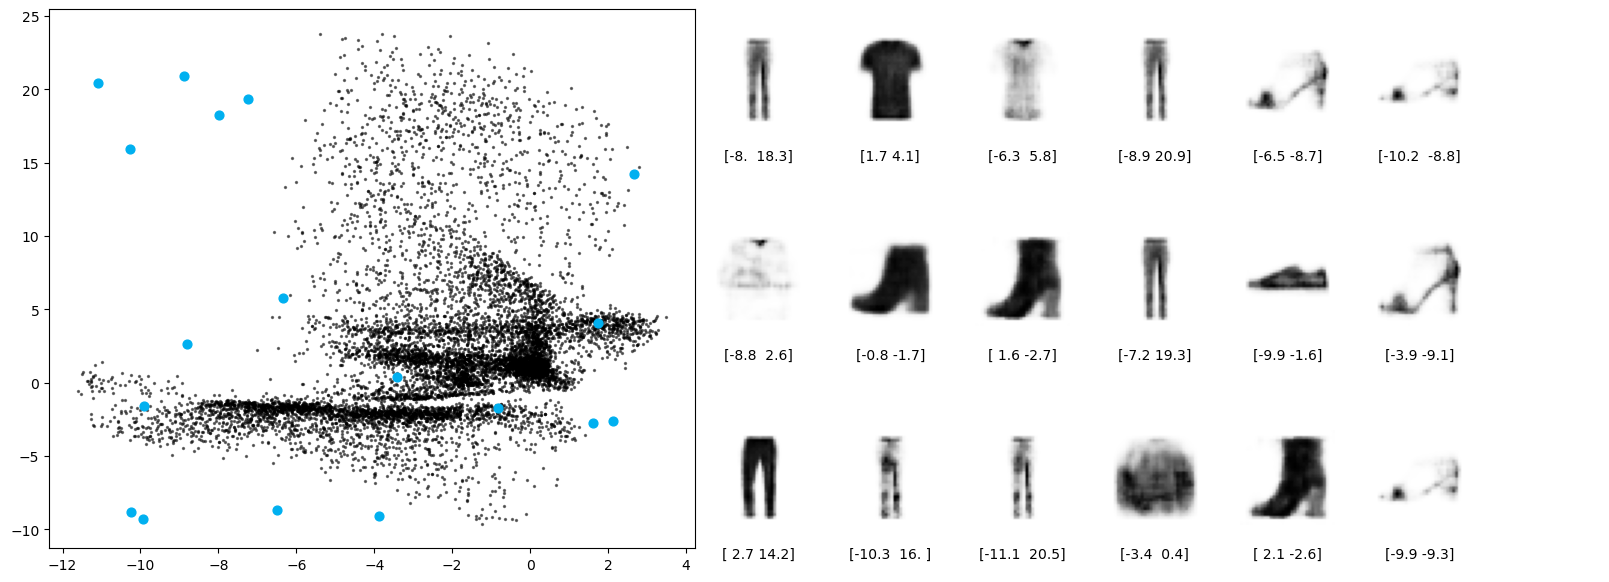

In [18]:
generating(x_test, encoder, decoder)

## Manifold

In [19]:
def manifold(X, encoder, decoder, figsize=8, grid_size=15):
    z = encoder.predict(X, verbose=0)
    x = np.linspace(min(z[:, 0]), max(z[:, 0]), grid_size)
    y = np.linspace(max(z[:, 1]), min(z[:, 1]), grid_size)
    xv, yv = np.meshgrid(x, y)
    xv = xv.flatten()
    yv = yv.flatten()
    grid = np.array(list(zip(xv, yv)))
    reconstructions = decoder.predict(grid, verbose=0)
    fig = plt.figure(figsize=(figsize, figsize))
    fig.subplots_adjust(hspace=0.4, wspace=0.4)
    for i in range(grid_size**2):
        ax = fig.add_subplot(grid_size, grid_size, i + 1)
        ax.axis("off")
        ax.imshow(reconstructions[i, :, :], cmap="Greys")
    plt.show()

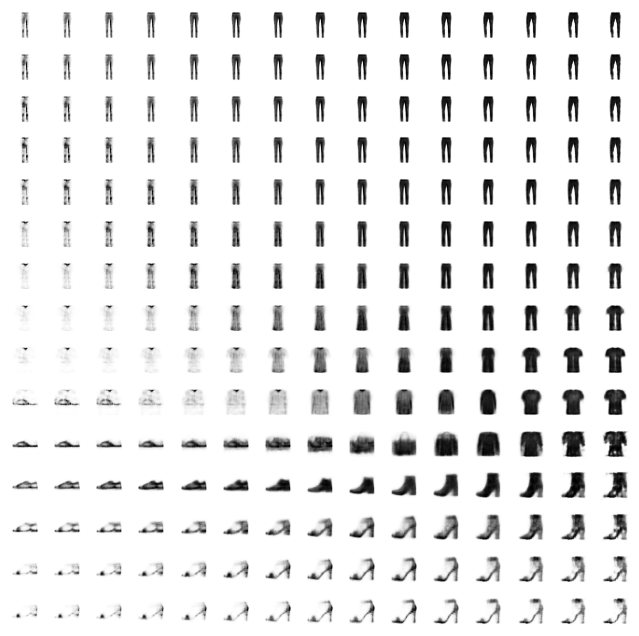

In [20]:
manifold(x_test, encoder, decoder)

# Variational Autoencoder

Un VAE es un autoencoder que proporciona una manera probabilística de describir una observación en el espacio latente. Por lo tanto, en lugar de generar un valor único para describir cada atributo de estado latente, describe una distribución de probabilidad para cada atributo latente.

<div align="center">
    <img src="img/vae.png" alt="" width="60%" align="center" />
</div>

## The CelebA Dataset

Usaremos el conjunto de datos [CelebFaces Attributes (CelebA)](http://mmlab.ie.cuhk.edu.hk/projects/CelebA.html). Se trata de una colección de más de 200.000 imágenes en color de rostros de celebridades, cada una con varias etiquetas (por ejemplo, con sombrero, sonriendo, etc.).

<div align="center">
    <img src="img/CelebFaces.jpg" alt="" width="45%" align="center" />
</div>

In [3]:
from keras.utils import image_dataset_from_directory

In [4]:
train_data = image_dataset_from_directory(
    "img_align_celeba",
    labels=None,
    color_mode="rgb",
    image_size=(64, 64),
    batch_size=128,
    shuffle=True,
    seed=42,
    interpolation="bilinear",
)

Found 202599 files belonging to 1 classes.


In [5]:
def preprocess(img):
    img = tf.cast(img, "float32") / 255.0
    return img

In [6]:
train = train_data.map(lambda x: preprocess(x))

## La arquitectura del VAE

<div align="center">
    <img src="img/vae-architecture-diagram.jpg" alt="" width="60%" align="center" />
</div>

## El truco de la reparametrización

Como el muestreo aleatorio no es diferenciable porque no podemos retropropagar a través de un nodo aleatorio, en el caso de los VAE, se usa el truco de la reparametrización, que cambia la fuente de aleatoriedad a otra variable diferente de $z$ (el vector latente), de modo que ahora puedes diferenciar con respecto a $z$.

El codificador aprende `z_mean` y `z_log_var` y los combina con ruido normal estándar, de modo que los gradientes ahora están disponibles para el codificador.

$$N(μ, σ) \sim N(0, 1) * σ μ$$


In [7]:
from keras.layers import Layer

In [8]:
class Sampling(Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        epsilon = K.random_normal(shape=(batch, dim))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

## Encoder

En un autoencoder, cada imagen se asigna directamente a un punto del espacio latente. En un variational autoencoder, cada imagen se asigna a una distribución normal multivariada alrededor de un punto en el espacio latente.

<div align="center">
    <img src="img/vae-encoder.jpg" alt="" width="60%" align="center" />
</div>

In [9]:
from keras.layers import LeakyReLU, BatchNormalization

In [10]:
encoder_input = Input(shape=(64, 64, 3), name="encoder_input")
x = Conv2D(64, kernel_size=3, strides=2, padding="same")(encoder_input)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Conv2D(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Conv2D(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Conv2D(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Conv2D(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
shape_before_flattening = K.int_shape(x)[1:]  

x = Flatten()(x)
z_mean = Dense(200, name="z_mean")(x)
z_log_var = Dense(200, name="z_log_var")(x)
z = Sampling()([z_mean, z_log_var])

encoder = Model(encoder_input, [z_mean, z_log_var, z], name="encoder")
encoder.summary()

Model: "encoder"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 encoder_input (InputLayer)     [(None, 64, 64, 3)]  0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 32, 32, 64)   1792        ['encoder_input[0][0]']          
                                                                                                  
 batch_normalization (BatchNorm  (None, 32, 32, 64)  256         ['conv2d[0][0]']                 
 alization)                                                                                       
                                                                                                  
 leaky_re_lu (LeakyReLU)        (None, 32, 32, 64)   0           ['batch_normalization[0][0]

## Decoder

In [11]:
decoder_input = Input(shape=(200,), name="decoder_input")
x = Dense(np.prod(shape_before_flattening))(decoder_input)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Reshape(shape_before_flattening)(x)
x = Conv2DTranspose(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Conv2DTranspose(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Conv2DTranspose(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Conv2DTranspose(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
x = Conv2DTranspose(64, kernel_size=3, strides=2, padding="same")(x)
x = BatchNormalization()(x)
x = LeakyReLU()(x)
decoder_output = Conv2DTranspose(3, kernel_size=3, strides=1, activation="sigmoid", padding="same")(x)
decoder = Model(decoder_input, decoder_output)
decoder.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 decoder_input (InputLayer)  [(None, 200)]             0         
                                                                 
 dense (Dense)               (None, 256)               51456     
                                                                 
 batch_normalization_5 (Batc  (None, 256)              1024      
 hNormalization)                                                 
                                                                 
 leaky_re_lu_5 (LeakyReLU)   (None, 256)               0         
                                                                 
 reshape (Reshape)           (None, 2, 2, 64)          0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 4, 4, 64)         36928     
 nspose)                                                     

## Variational Autoencoder Model

In [12]:
from keras import metrics, losses

In [13]:
class VAE(Model):
    def __init__(self, encoder, decoder, **kwargs):
        super(VAE, self).__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.total_loss_tracker = metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = metrics.Mean(
            name="reconstruction_loss"
        )
        self.kl_loss_tracker = metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs):
        """Call the model on a particular input."""
        z_mean, z_log_var, z = encoder(inputs)
        reconstruction = decoder(z)
        return z_mean, z_log_var, reconstruction

    def train_step(self, data):
        """Step run during training."""
        with tf.GradientTape() as tape:
            z_mean, z_log_var, reconstruction = self(data, training=True)
            reconstruction_loss = tf.reduce_mean(
                2000 * losses.mean_squared_error(data, reconstruction)
            )
            kl_loss = tf.reduce_mean(
                tf.reduce_sum(
                    -0.5
                    * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)),
                    axis=1,
                )
            )
            total_loss = reconstruction_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss": self.reconstruction_loss_tracker.result(),
            "kl_loss": self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        """Step run during validation."""
        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, reconstruction = self(data)
        reconstruction_loss = tf.reduce_mean(
            2000 * losses.mean_squared_error(data, reconstruction)
        )
        kl_loss = tf.reduce_mean(
            tf.reduce_sum(
                -0.5 * (1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var)),
                axis=1,
            )
        )
        total_loss = reconstruction_loss + kl_loss

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss,
        }

In [14]:
vae = VAE(encoder, decoder)

## La función de pérdida (Loss)

Anteriormente, nuestra función Loss solo consistía en la pérdida de reconstrucción entre imágenes y sus intentos de copia después de pasar por el codificador y decodificador. La pérdida de reconstrucción también aparece en un VAE, pero ahora necesitamos incluir un componente adicional: la divergencia de Kullback-Leibler (KL). 

La divergencia KL es una forma de medir en qué medida una distribución de probabilidad difiere de otra.

$${\displaystyle D_{\mathrm {KL} }(P\|Q)=\sum _{i}P(i)\log {\frac {P(i)}{Q(i)}}},$$

donde $P$ y $Q$ son funciones de densidad de probabilidad (PDF) de distribuciones. Sabemos que $\log(1)=0$, entonces cuando $P$ y $Q$ son iguales, $D_{\mathrm {KL} }=0$.


In [15]:
from keras import optimizers

In [16]:
optimizer = optimizers.Adam(learning_rate=0.0005)
vae.compile(optimizer=optimizer)

## Entrenamiento

In [17]:
from vae_utils import get_vector_from_label, add_vector_to_images, morph_faces

In [18]:
from keras import callbacks

In [19]:
model_checkpoint_callback = callbacks.ModelCheckpoint(
    filepath="./checkpoint",
    save_weights_only=False,
    save_freq="epoch",
    monitor="loss",
    mode="min",
    save_best_only=True,
    verbose=0,
)

tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")


class ImageGenerator(callbacks.Callback):
    def __init__(self, num_img, latent_dim):
        self.num_img = num_img
        self.latent_dim = latent_dim

    def on_epoch_end(self, epoch, logs=None):
        random_latent_vectors = tf.random.normal(
            shape=(self.num_img, self.latent_dim)
        )
        generated_images = self.model.decoder(random_latent_vectors)
        generated_images *= 255
        generated_images.numpy()
        for i in range(self.num_img):
            img = utils.array_to_img(generated_images[i])
            img.save("./output/generated_img_%03d_%d.png" % (epoch, i))

### Cargar los pesos

In [20]:
vae.load_weights("./models/vae")
tmp = vae.predict(train.take(1))

1/1 [==============================] - 1s 1s/step


### Ajustar pesos

In [ ]:
vae.fit(train, epochs=5, callbacks=[
        model_checkpoint_callback,
        tensorboard_callback,
        ImageGenerator(num_img=10, latent_dim=200),
    ])

### Guardar los pesos

In [ ]:
vae.save("./models/vae")
encoder.save("./models/encoder")
decoder.save("./models/decoder")

## Distribuciones

Distribuciones de puntos para las primeras 50 dimensiones en el espacio latente.

In [21]:
from scipy.stats import norm

In [22]:
def plot_distributions(vae):
    batches_to_predict = 1
    example_images = np.array(
        list(train.take(batches_to_predict).get_single_element())
    )
    _, _, z = vae.encoder.predict(example_images, verbose=0)
    x = np.linspace(-3, 3, 100)
    fig = plt.figure(figsize=(20, 5))
    fig.subplots_adjust(hspace=0.6, wspace=0.4)
    fig.suptitle("Distribuciones de puntos para las primeras 50 dimensiones en el espacio latente")
    for i in range(50):
        ax = fig.add_subplot(5, 10, i + 1)
        ax.hist(z[:, i], density=True, bins=20)
        ax.axis("off")
        ax.text(0.5, -0.35, str(i), fontsize=10, ha="center", transform=ax.transAxes)
        ax.plot(x, norm.pdf(x))
    plt.show()

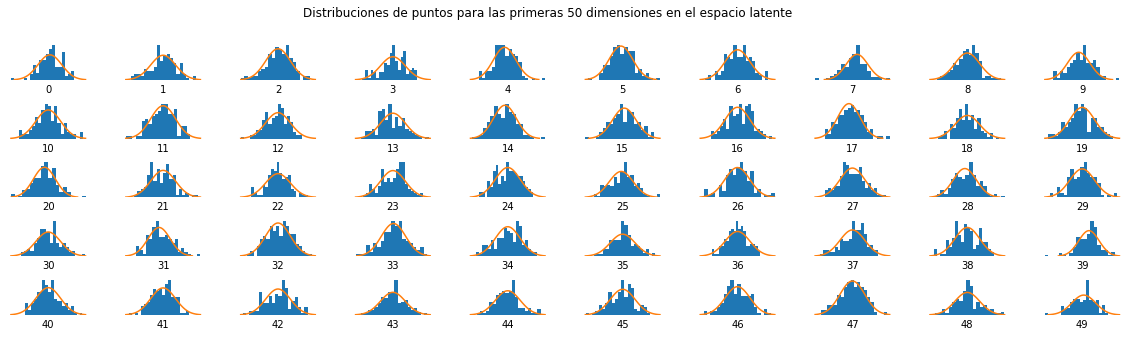

In [23]:
plot_distributions(vae)

## Generar caras nuevas

In [24]:
def plot_new_faces(decoder, grid_width=10, grid_height=3):   
    z_sample = np.random.normal(size=(grid_width * grid_height, 200))    
    reconstructions = decoder.predict(z_sample, verbose=0)    
    fig = plt.figure(figsize=(18, 5))
    fig.subplots_adjust(hspace=0.4, wspace=0.4)    
    for i in range(grid_width * grid_height):
        ax = fig.add_subplot(grid_height, grid_width, i + 1)
        ax.axis("off")
        ax.imshow(reconstructions[i, :, :])

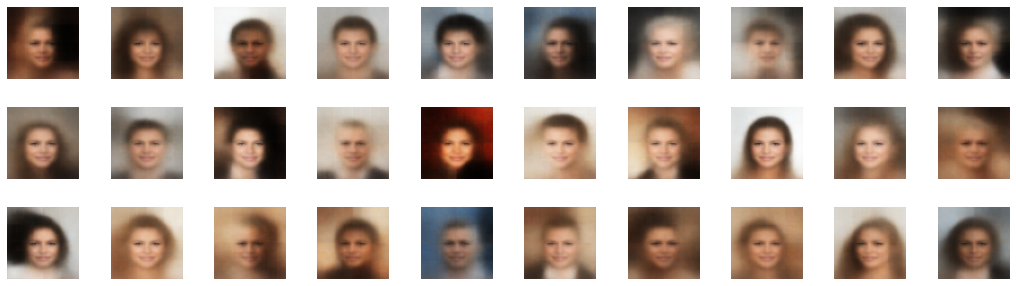

In [25]:
plot_new_faces(decoder)

## Aritmética del espacio latente

Un beneficio de mapear imágenes en un espacio latente de dimensiones inferiores es que podemos realizar aritmética sobre vectores en este espacio latente.

Por ejemplo, supongamos que queremos tomar una imagen de alguien que parece triste y hacerlo sonreír. Primero necesitamos encontrar un vector en el espacio latente que apunte en la dirección de la sonrisa creciente. Sumar este vector a la codificación de la imagen original en el espacio latente nos dará un nuevo punto que, cuando se decodifique, debería darnos una versión más sonriente de la imagen original.

Conceptualmente, estamos realizando la siguiente aritmética vectorial en el espacio latente, donde $\alpha$ es un factor que determina qué parte del vector de características se suma o resta:
$$ z_{new} = z + \alpha * \mbox{feature_vector}$$

In [26]:
import pandas as pd

In [27]:
attributes = pd.read_csv("list_attr_celeba.csv")

In [28]:
attributes.head()

,File_name,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1


In [29]:
print(list(attributes.columns))

['File_name', '5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young']


### Atributo `Blond_Hair`

In [30]:
labelled_test = image_dataset_from_directory(
    "img_align_celeba",
    labels=attributes["Blond_Hair"].tolist(),
    color_mode="rgb",
    image_size=(64, 64),
    batch_size=128,
    shuffle=True,
    seed=42,
    validation_split=0.2,
    subset="validation",
    interpolation="bilinear",
)

labelled = labelled_test.map(lambda x, y: (preprocess(x), y))

Found 202599 files belonging to 2 classes.
Using 40519 files for validation.


### Obtener el vector de atributos

In [31]:
attribute_vec = get_vector_from_label(labelled, vae, 200, "Blond_Hair")

Found the Blond_Hair vector


### Sumar vector a las imágenes

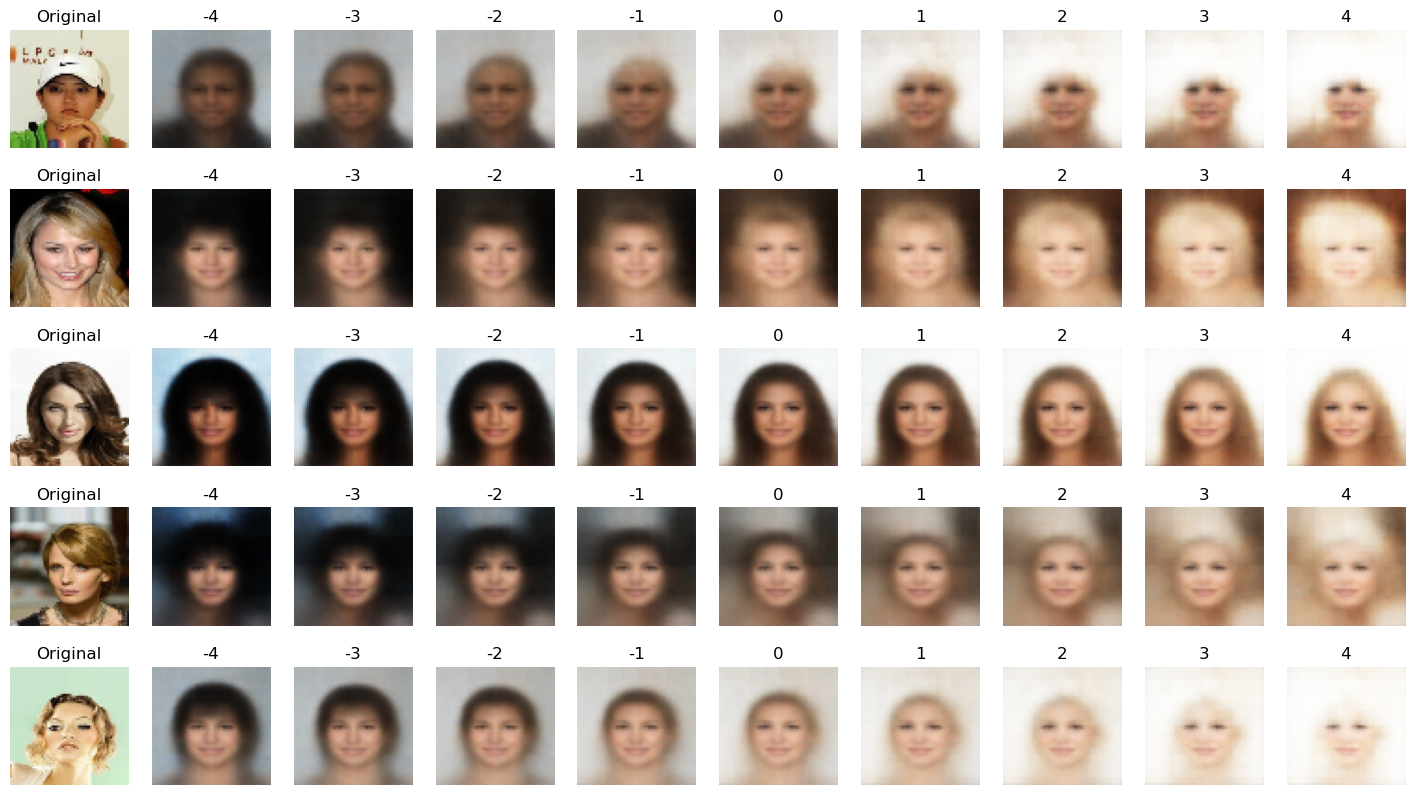

In [50]:
add_vector_to_images(labelled, vae, attribute_vec)

### Atributo `Bald`

In [51]:
labelled_test = image_dataset_from_directory(
    "img_align_celeba",
    labels=attributes["Bald"].tolist(),
    color_mode="rgb",
    image_size=(64, 64),
    batch_size=128,
    shuffle=True,
    seed=42,
    validation_split=0.2,
    subset="validation",
    interpolation="bilinear",
)

labelled = labelled_test.map(lambda x, y: (preprocess(x), y))

Found 202599 files belonging to 2 classes.
Using 40519 files for validation.


In [52]:
attribute_vec = get_vector_from_label(labelled, vae, 200, "Bald")

Found the Bald vector


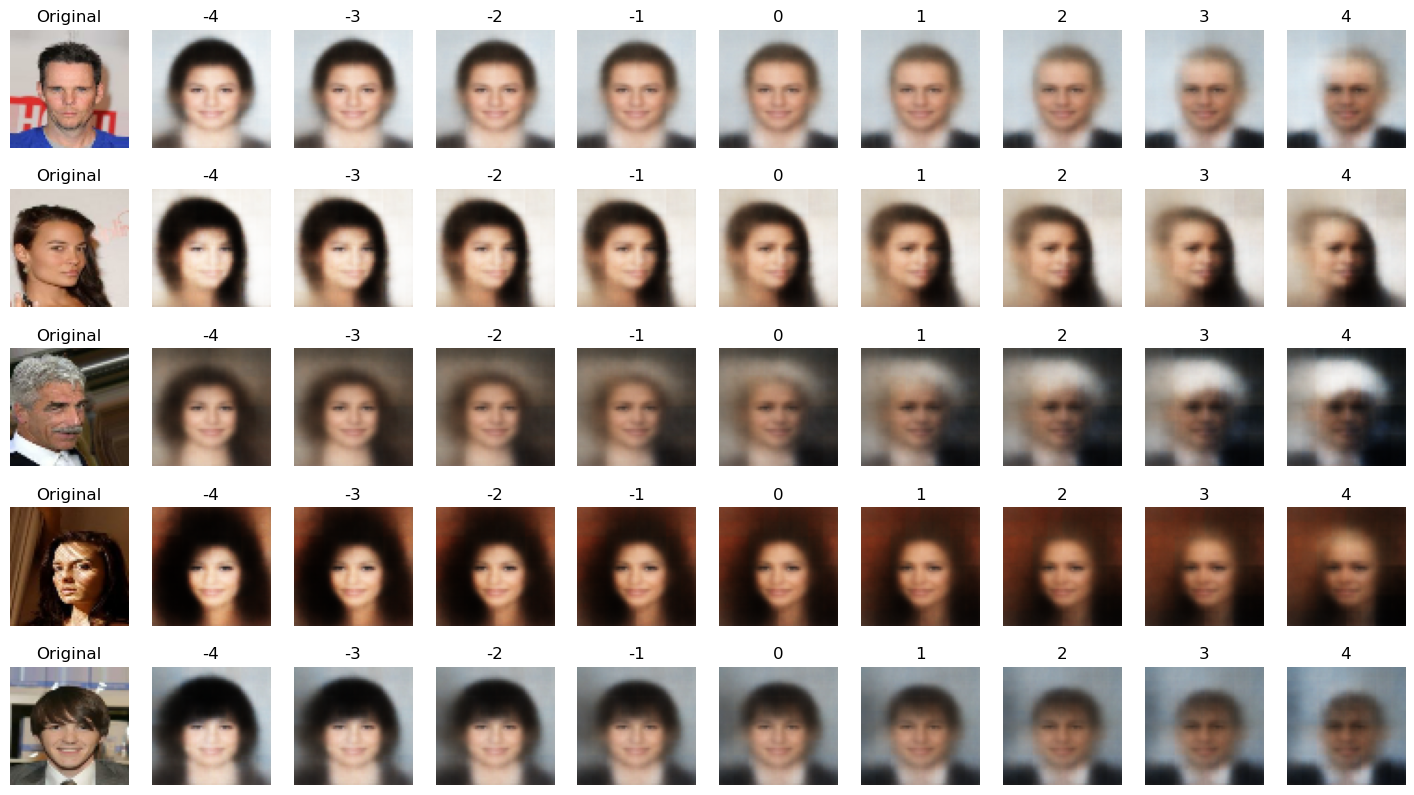

In [53]:
add_vector_to_images(labelled, vae, attribute_vec)

### Atributo `Male`

In [54]:
labelled_test = image_dataset_from_directory(
    "img_align_celeba",
    labels=attributes["Male"].tolist(),
    color_mode="rgb",
    image_size=(64, 64),
    batch_size=128,
    shuffle=True,
    seed=42,
    validation_split=0.2,
    subset="validation",
    interpolation="bilinear",
)

labelled = labelled_test.map(lambda x, y: (preprocess(x), y))

Found 202599 files belonging to 2 classes.
Using 40519 files for validation.


In [55]:
attribute_vec = get_vector_from_label(labelled, vae, 200, "Male")

Found the Male vector


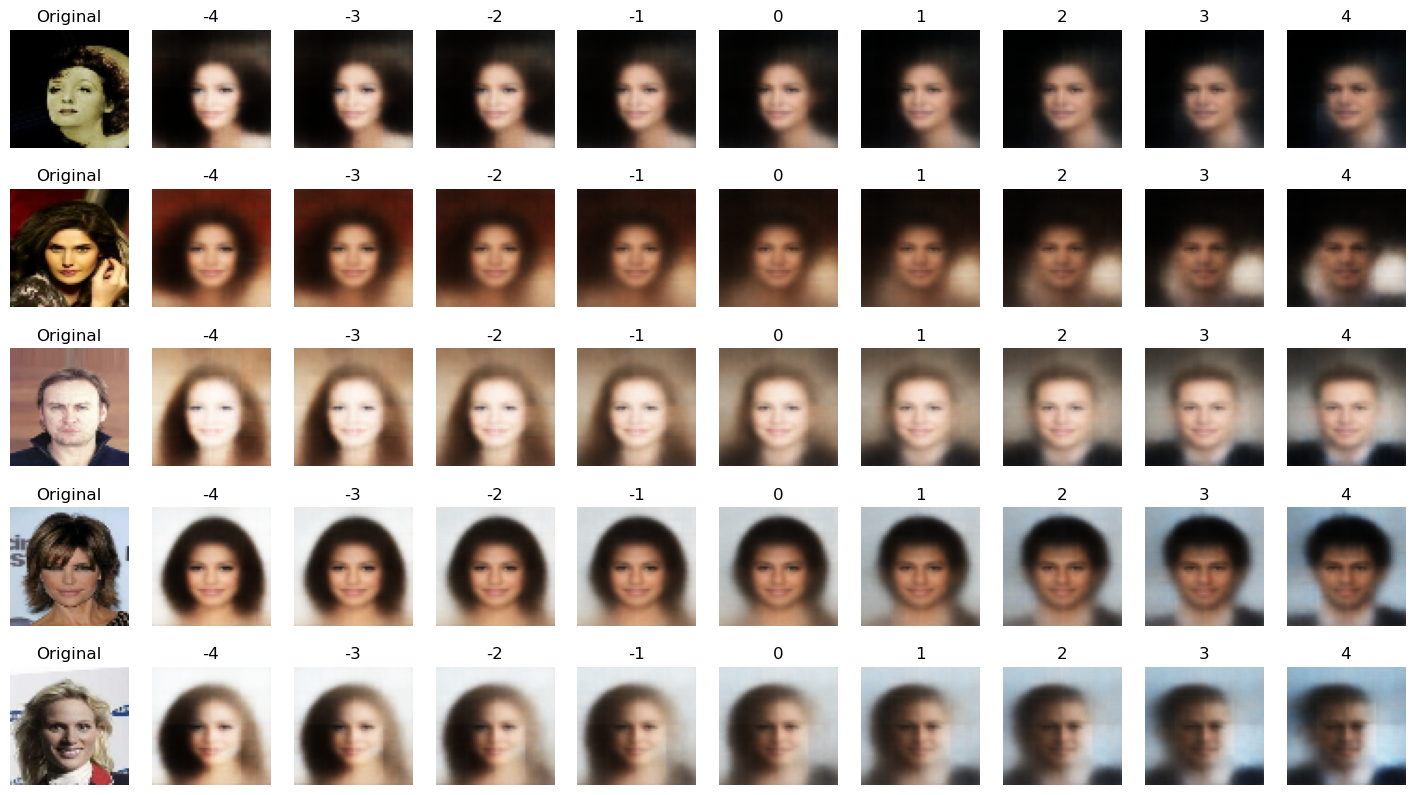

In [56]:
add_vector_to_images(labelled, vae, attribute_vec)

## Transformación entre caras

Imagine dos puntos en el espacio latente, A y B, que representan dos imágenes. Si comenzamos en el punto A y caminamos hacia el punto B en línea recta, decodificando cada punto de la línea a medida que avanzamos, veríamos una transición gradual desde la cara inicial hasta la cara final.

Matemáticamente, estamos atravesando una línea recta, que puede describirse mediante la siguiente ecuación:

$$z_{new} = z_A * (1- \alpha) + z_B * \alpha$$

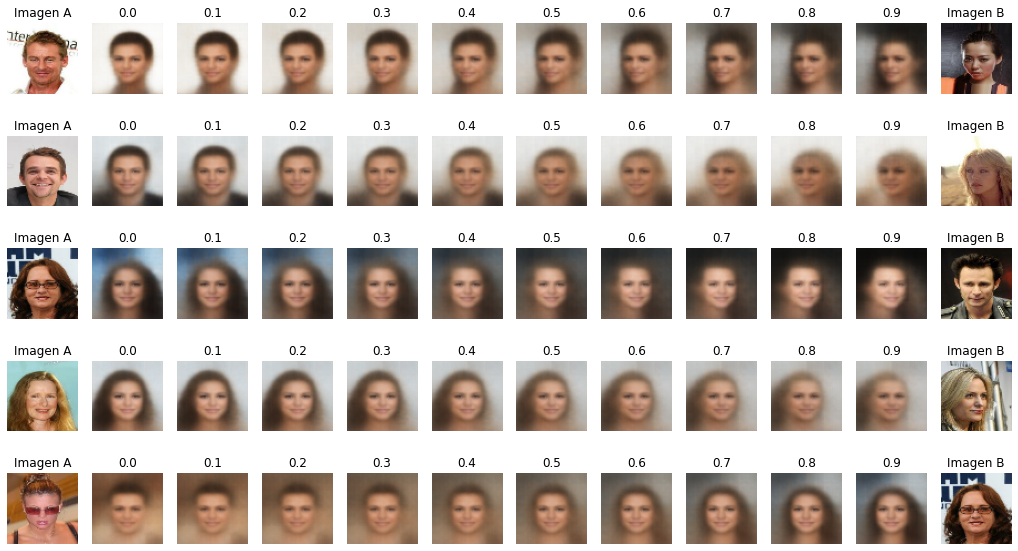

In [33]:
morph_faces(labelled, vae)